# Phase 2 of 3: Baselines (TF-IDF Logistic Regression and XGBoost)

**Run order:** 2 of 4. Needs the Phase 1 outputs in `data/source-clean-v1/`; the first cell asserts them.
**Produces:** `models/phase2-v1-<fingerprint>/` with both models, calibrators, `thresholds.json`, `metrics.json`, `run_manifest.json` and plots.
**Expect:** a few minutes. TF-IDF fitting is CPU-bound; XGBoost uses CUDA when present. The chosen baseline printed at the end is the bar Phase 3 must clear.

Two baselines on the Phase 1 `v1` splits, per `docs/PLAN.md` §3 Stage A:

1. **TF-IDF + logistic regression**: word 1-2 grams and character 3-5 grams, cased, over the
   raw text. The strongest cheap text model; the bar the neural model has to clear.
2. **XGBoost on the engineered features** from the datagen notebook: the explainable,
   surface-feature baseline.

Discipline, identical to `email-classifier-nn` Phase 2: `train` fits parameters; `val` alone drives
early stopping, Platt calibration, threshold selection and model selection; `test` and
`adversarial_test` are opened once, in the last section. Every locked number comes with a 95%
bootstrap confidence interval, a recall-at-FPR table, and per-source and per-shape slices
(`docs/EVALUATION.md` §3-4). The reason head does not exist at this stage; Phase 2 is binary only.

Runs unchanged on CUDA, Apple MPS, or CPU. Output: `models/phase2-v1-<fingerprint>/`.


## 1. Environment


In [1]:
%pip install -q xgboost==3.4.0 matplotlib==3.11.1


Note: you may need to restart the kernel to use updated packages.


In [2]:
import gc
import json
import os
import platform
import random
import sys
from contextlib import nullcontext
from datetime import datetime, timezone
from importlib.metadata import version as package_version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
from sklearn.calibration import calibration_curve
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from xgboost import XGBClassifier

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    try:
        torch.cuda.set_per_process_memory_fraction(0.55, 0)
    except RuntimeError as exc:
        print(f"CUDA memory cap was not applied: {exc}")

print({"python": sys.version.split()[0], "torch": package_version("torch"), "xgboost": package_version("xgboost"),
       "scikit_learn": package_version("scikit-learn")})

# Resolve the project root so this notebook runs unchanged on the DGX Spark (container or
# host), a Mac, or any other checkout: env var first, then the Spark paths, then walk up
# from the working directory until a folder containing docs/PLAN.md is found.
def resolve_project_dir():
    candidates = [
        Path(p) for p in (
            os.environ.get("PI_NN_DIR"),
            "/workspace/training/prompt-injection-nn",
            "/home/spark/projects/training/prompt-injection-nn",
        ) if p
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (parent / "docs" / "PLAN.md").exists() and (parent / "notebooks").is_dir():
            return parent
    raise FileNotFoundError(f"project root not found; tried {candidates} and parents of {Path.cwd()}")

def resolve_device():
    # CUDA (DGX Spark) > MPS (Apple Silicon) > CPU. Nothing else in the notebook is device-specific.
    if torch.cuda.is_available():
        return torch.device("cuda")
    mps = getattr(torch.backends, "mps", None)
    if mps is not None and mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def amp_context(device, use_bf16):
    # BF16 autocast only on CUDA. MPS autocast support varies by torch version; CPU gains nothing here.
    if use_bf16 and device.type == "cuda":
        return torch.autocast(device_type="cuda", dtype=torch.bfloat16)
    return nullcontext()


def empty_device_cache(device):
    if device.type == "cuda":
        torch.cuda.empty_cache()
    elif device.type == "mps" and hasattr(torch, "mps"):
        torch.mps.empty_cache()

# Output contract shared with the LoRA and the Open WebUI filter: "SAFE" or "INJECTION: <reason>".
REASONS = [
    "Override Attempt",
    "Fake System Injection",
    "Meta-Command Injection",
    "Jailbreak Technique",
    "Delimiter Confusion",
    "Privilege Escalation",
    "Embedded Instruction",
    "Role-Play Bypass",
    "Chain-of-Instructions",
]


{'python': '3.12.3', 'torch': '2.10.0a0+b558c986e8.nv25.11', 'xgboost': '3.4.0', 'scikit_learn': '1.7.2'}


## 2. Load and Validate Phase 1 Artifacts


In [3]:
DATASET_VERSION = "v3"  # v1 and v2 are superseded; see README "Progress and findings". Frozen, never retrained against.
PROJECT_DIR = resolve_project_dir()
DATA_DIR = PROJECT_DIR / "data" / f"source-clean-{DATASET_VERSION}"
MANIFEST_PATH = DATA_DIR / "manifest.json"
assert DATA_DIR.exists(), f"{DATASET_VERSION} splits missing: {DATA_DIR} (run the datagen notebook first)"
SPLIT_PATHS = {name: DATA_DIR / f"{name}.parquet" for name in ("train", "val", "test", "adversarial_test")}

manifest = json.loads(MANIFEST_PATH.read_text())
PHASE1_FINGERPRINT = manifest["config_fingerprint"]
FEATURE_COLS = list(manifest["feature_columns"])
assert manifest["reasons"] == REASONS, "reason taxonomy drifted between datagen and this notebook"

frames = {name: pd.read_parquet(path) for name, path in SPLIT_PATHS.items()}
for name, frame in frames.items():
    expected = manifest["counts"][name]
    assert len(frame) == expected["rows"], (name, len(frame), expected["rows"])
    assert int(frame["label"].sum()) == expected["injection"]
    assert int((frame["label"] == 0).sum()) == expected["safe"]
    assert int(frame["augmented"].sum()) == expected["augmented"]
    assert set(FEATURE_COLS).issubset(frame.columns)
    assert frame[FEATURE_COLS].notna().all().all()
    assert set(frame["label"].unique()).issubset({0, 1})
    assert ((frame["label"] == 0) & (frame["reason"] == "")).sum() + ((frame["label"] == 1) & frame["reason"].isin(REASONS)).sum() == len(frame)

assert not frames["val"]["augmented"].any()
assert not frames["test"]["augmented"].any()
assert frames["adversarial_test"]["augmented"].all()
assert frames["adversarial_test"]["label"].eq(1).all()

texts = {name: frame["text"].fillna("").astype(str).tolist() for name, frame in frames.items()}
X_feat = {name: frame[FEATURE_COLS].to_numpy(dtype=np.float32) for name, frame in frames.items()}
y = {name: frame["label"].to_numpy(dtype=np.int64) for name, frame in frames.items()}

run_id = f"phase2-{DATASET_VERSION}-{PHASE1_FINGERPRINT[:16]}"
OUTPUT_DIR = PROJECT_DIR / "models" / run_id
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print({name: len(frame) for name, frame in frames.items()})
print("feature order:", FEATURE_COLS)
print("output:", OUTPUT_DIR)


{'train': 47570, 'val': 5419, 'test': 5419, 'adversarial_test': 2102}
feature order: ['f_len_chars', 'f_n_words', 'f_delim_runs', 'f_angle_tags', 'f_special_tokens', 'f_imperative_density', 'f_model_address', 'f_lexicon_hits', 'f_zero_width', 'f_homoglyph', 'f_base64_runs', 'f_url_count', 'f_brackets', 'f_newlines', 'f_upper_ratio', 'f_digit_ratio', 'f_nonascii_ratio']
output: /workspace/training/prompt-injection-nn/models/phase2-v3-a4c8dd4786013cfd


## 3. Metric Helpers

Shared, byte-identical with Phase 3 and the eval notebook.


In [4]:
def binary_metrics(y_true, probabilities, threshold):
    probabilities = np.asarray(probabilities, dtype=np.float64)
    predictions = (probabilities >= threshold).astype(np.int64)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold),
        "precision": float(precision_score(y_true, predictions, zero_division=0)),
        "recall": float(recall_score(y_true, predictions, zero_division=0)),
        "f1": float(f1_score(y_true, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, probabilities)) if len(set(y_true)) > 1 else None,
        "average_precision": float(average_precision_score(y_true, probabilities)) if len(set(y_true)) > 1 else None,
        "brier": float(brier_score_loss(y_true, probabilities)),
        "log_loss": float(log_loss(y_true, probabilities, labels=[0, 1])),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "specificity": float(tn / (tn + fp)) if tn + fp else None,
        "false_positive_rate": float(fp / (tn + fp)) if tn + fp else None,
    }


def adversarial_metrics(probabilities, threshold):
    # The adversarial set is all-positive: only recall and the probability distribution are defined.
    probabilities = np.asarray(probabilities, dtype=np.float64)
    return {
        "threshold": float(threshold),
        "injection_recall": float(np.mean(probabilities >= threshold)),
        "probability_mean": float(probabilities.mean()),
        "probability_median": float(np.median(probabilities)),
        "probability_min": float(probabilities.min()),
        "probability_max": float(probabilities.max()),
    }


def select_threshold(y_true, probabilities):
    # Max validation F1; ties broken by higher recall, then lower threshold.
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)
    candidates = []
    for index, threshold in enumerate(thresholds):
        denominator = precision[index] + recall[index]
        score = 0.0 if denominator == 0 else 2 * precision[index] * recall[index] / denominator
        candidates.append((score, recall[index], -threshold, threshold))
    return float(max(candidates)[3])


FPR_BUDGETS = (0.01, 0.005, 0.001)


def recall_at_fpr(y_true, probabilities, budgets=FPR_BUDGETS):
    # For each FPR budget: the lowest threshold whose FPR on these rows is within budget, and the
    # recall there. This is the deployment table: how much injection is caught per dropped-benign budget.
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    negatives = np.sort(probabilities[y_true == 0])
    positives = probabilities[y_true == 1]
    table = {}
    for budget in budgets:
        allowed = int(np.floor(budget * len(negatives)))
        # threshold just above the (allowed)-th highest negative score
        threshold = float(np.nextafter(negatives[-allowed - 1], 1.0)) if allowed < len(negatives) else 0.0
        fpr = float(np.mean(negatives >= threshold)) if len(negatives) else 0.0
        table[f"fpr_{budget:g}"] = {
            "threshold": threshold,
            "recall": float(np.mean(positives >= threshold)) if len(positives) else None,
            "achieved_fpr": fpr,
            "allowed_false_positives": allowed,
        }
    return table


def bootstrap_ci(y_true, probabilities, threshold, n_resamples=1000, seed=42, alpha=0.05):
    # Percentile bootstrap over rows. Reported with every locked-test number so a single point
    # estimate is never presented as the result.
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    rng = np.random.default_rng(seed)
    predictions = (probabilities >= threshold).astype(np.int64)
    samples = {"average_precision": [], "roc_auc": [], "f1": [], "recall": [], "false_positive_rate": []}
    n = len(y_true)
    for _ in range(n_resamples):
        index = rng.integers(0, n, n)
        yt, pr, pd_ = y_true[index], probabilities[index], predictions[index]
        if yt.min() == yt.max():
            continue
        tp = int(((pd_ == 1) & (yt == 1)).sum()); fp = int(((pd_ == 1) & (yt == 0)).sum())
        fn = int(((pd_ == 0) & (yt == 1)).sum()); tn = int(((pd_ == 0) & (yt == 0)).sum())
        samples["average_precision"].append(average_precision_score(yt, pr))
        samples["roc_auc"].append(roc_auc_score(yt, pr))
        samples["f1"].append(2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0)
        samples["recall"].append(tp / (tp + fn) if tp + fn else 0.0)
        samples["false_positive_rate"].append(fp / (fp + tn) if fp + tn else 0.0)
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        key: {"low": float(np.percentile(values, lo)), "high": float(np.percentile(values, hi)), "resamples": len(values)}
        for key, values in samples.items()
    }


def slice_metrics(frame, probabilities, threshold, column):
    # Per-slice metrics. Single-class slices (all SAFE or all INJECTION) report only what is defined.
    rows = {}
    probabilities = np.asarray(probabilities, dtype=np.float64)
    for value, index in frame.groupby(column).indices.items():
        y = frame["label"].to_numpy()[index]
        p = probabilities[index]
        predictions = (p >= threshold).astype(int)
        entry = {"rows": int(len(index)), "injection_rows": int(y.sum()), "safe_rows": int((y == 0).sum())}
        if y.sum():
            entry["recall"] = float(predictions[y == 1].mean())
        if (y == 0).sum():
            entry["false_positive_rate"] = float(predictions[y == 0].mean())
        if 0 < y.sum() < len(y):
            entry["f1"] = float(f1_score(y, predictions, zero_division=0))
            entry["average_precision"] = float(average_precision_score(y, p))
        rows[str(value)] = entry
    return rows


def atomic_json(payload, path):
    temporary = Path(str(path) + ".tmp")
    temporary.write_text(json.dumps(payload, indent=2, sort_keys=True, default=str))
    os.replace(temporary, path)


def fit_sigmoid_calibrator(y_true, probabilities):
    clipped = np.clip(probabilities, 1e-7, 1 - 1e-7)
    logits = np.log(clipped / (1 - clipped)).reshape(-1, 1)
    calibrator = LogisticRegression(random_state=SEED, solver="lbfgs")
    calibrator.fit(logits, y_true)
    return calibrator


def apply_calibrator(calibrator, probabilities):
    clipped = np.clip(probabilities, 1e-7, 1 - 1e-7)
    logits = np.log(clipped / (1 - clipped)).reshape(-1, 1)
    return calibrator.predict_proba(logits)[:, 1]


## 4. TF-IDF Logistic Regression

Cased word 1-2 grams plus cased character 3-5 grams (`char_wb`), fitted on train only. Case is
kept because `IGNORE ALL PREVIOUS INSTRUCTIONS` and `<|im_start|>` are signal, not noise
(`PLAN.md` §3). `class_weight="balanced"` instead of resampling.


In [5]:
TFIDF_CONFIG = {
    "word": {"analyzer": "word", "ngram_range": (1, 2), "min_df": 2, "max_features": 200000,
             "sublinear_tf": True, "lowercase": False, "token_pattern": r"(?u)\b\w+\b|[^\w\s]+"},
    "char": {"analyzer": "char_wb", "ngram_range": (3, 5), "min_df": 2, "max_features": 300000,
             "sublinear_tf": True, "lowercase": False},
}
LOGREG_CONFIG = {"C": 2.0, "class_weight": "balanced", "max_iter": 3000, "solver": "liblinear", "random_state": SEED}

tfidf_word = TfidfVectorizer(**TFIDF_CONFIG["word"])
tfidf_char = TfidfVectorizer(**TFIDF_CONFIG["char"])
X_tfidf = {"train": sp.hstack([tfidf_word.fit_transform(texts["train"]), tfidf_char.fit_transform(texts["train"])]).tocsr()}
for name in ("val", "test", "adversarial_test"):
    X_tfidf[name] = sp.hstack([tfidf_word.transform(texts[name]), tfidf_char.transform(texts[name])]).tocsr()
print({name: matrix.shape for name, matrix in X_tfidf.items()})

logreg = LogisticRegression(**LOGREG_CONFIG)
logreg.fit(X_tfidf["train"], y["train"])
logreg_val_raw = logreg.predict_proba(X_tfidf["val"])[:, 1]
logreg_calibrator = fit_sigmoid_calibrator(y["val"], logreg_val_raw)
logreg_val_probability = apply_calibrator(logreg_calibrator, logreg_val_raw)
logreg_threshold = select_threshold(y["val"], logreg_val_probability)
logreg_validation = binary_metrics(y["val"], logreg_val_probability, logreg_threshold)

joblib.dump(tfidf_word, OUTPUT_DIR / "tfidf_word.joblib")
joblib.dump(tfidf_char, OUTPUT_DIR / "tfidf_char.joblib")
joblib.dump(logreg, OUTPUT_DIR / "logreg.joblib")
joblib.dump(logreg_calibrator, OUTPUT_DIR / "logreg_calibrator.joblib")
print(logreg_validation)

# The most positive and most negative weights: a first look at what the linear model keys on.
feature_names = np.concatenate([tfidf_word.get_feature_names_out(), tfidf_char.get_feature_names_out()])
order = np.argsort(logreg.coef_[0])
print("top injection n-grams:", [feature_names[i] for i in order[-25:][::-1]])
print("top safe n-grams:     ", [feature_names[i] for i in order[:25]])


{'train': (47570, 500000), 'val': (5419, 500000), 'test': (5419, 500000), 'adversarial_test': (2102, 500000)}
{'threshold': 0.4202061292432554, 'precision': 0.8501350135013501, 'recall': 0.8986679352997146, 'f1': 0.8737280296022202, 'roc_auc': 0.9656432121582241, 'average_precision': 0.9487960379153622, 'brier': 0.07240210173705947, 'log_loss': 0.23125023078352136, 'tn': 2984, 'fp': 333, 'fn': 213, 'tp': 1889, 'specificity': 0.899608079589991, 'false_positive_rate': 0.10039192041000905}
top injection n-grams: [',', '"', '|', '?"', '."', 'a', '| |', '" Could', '? I', 'erotic', ' | ', '" Imagine', 'Dear', 'Dear language', '\u200b', '. to', '. you', '```', 'you please', 'а', '?" ', '." ', 'Create', 'thе', 'ng ']
top safe n-grams:      ['?', 'any explicit', '. Could', '(', 'Subject :', 'Subject', 'to the', '. In', '.', 'What', 'Imagine you', 'was', 'is', '),', 'explicit or', 'any harmful', ';', 'without causing', ', the', ' Imag', ' . ', ' Ima', 'To help', 'want to', 'a creative']


## 5. XGBoost on Engineered Features

CUDA `hist` when a GPU is present, CPU otherwise. The tree cap is high enough that early stopping, not the cap, ends training; the notebook says which one did.


In [6]:
XGB_CONFIG = {
    "n_estimators": 4000,
    "learning_rate": 0.05,
    "max_depth": 6,
    "min_child_weight": 2.0,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.0,
    "reg_lambda": 1.0,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",
    "device": "cuda" if torch.cuda.is_available() else "cpu",  # XGBoost has no MPS backend
    "early_stopping_rounds": 100,
    "random_state": SEED,
    "n_jobs": -1,
}

xgb_model = XGBClassifier(**XGB_CONFIG)
xgb_model.fit(X_feat["train"], y["train"], eval_set=[(X_feat["val"], y["val"])], verbose=100)
xgb_val_raw = xgb_model.predict_proba(X_feat["val"])[:, 1]
xgb_calibrator = fit_sigmoid_calibrator(y["val"], xgb_val_raw)
xgb_val_probability = apply_calibrator(xgb_calibrator, xgb_val_raw)
xgb_threshold = select_threshold(y["val"], xgb_val_probability)
xgb_validation = binary_metrics(y["val"], xgb_val_probability, xgb_threshold)

xgb_model.save_model(OUTPUT_DIR / "xgboost.json")
joblib.dump(xgb_calibrator, OUTPUT_DIR / "xgboost_calibrator.joblib")
xgb_stopped_early = xgb_model.best_iteration < XGB_CONFIG["n_estimators"] - 1
print("best_iteration:", xgb_model.best_iteration, "| early stopping fired" if xgb_stopped_early else "| CAP REACHED: raise n_estimators or learning_rate")
print(xgb_validation)


[0]	validation_0-logloss:0.65901
[100]	validation_0-logloss:0.43253
[200]	validation_0-logloss:0.41728
[300]	validation_0-logloss:0.41241
[400]	validation_0-logloss:0.41018
[500]	validation_0-logloss:0.40985
[573]	validation_0-logloss:0.41064
best_iteration: 473 | early stopping fired
{'threshold': 0.37414873407365423, 'precision': 0.6421450670333448, 'recall': 0.8886774500475737, 'f1': 0.7455597685092796, 'roc_auc': 0.87704389950338, 'average_precision': 0.8116732326938824, 'brier': 0.1380907899927453, 'log_loss': 0.4092040726943251, 'tn': 2276, 'fp': 1041, 'fn': 234, 'tp': 1868, 'specificity': 0.6861621947542961, 'false_positive_rate': 0.3138378052457039}


/usr/local/lib/python3.12/dist-packages/xgboost/core.py:569: UserWarning: [17:17:44] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


## 6. Validation-Only Calibration, Thresholds, Recall@FPR and Selection


              threshold  precision    recall        f1   roc_auc  \
tfidf_logreg   0.420206   0.850135  0.898668  0.873728  0.965643   
xgboost        0.374149   0.642145  0.888677  0.745560  0.877044   

              average_precision     brier  false_positive_rate  
tfidf_logreg           0.948796  0.072402             0.100392  
xgboost                0.811673  0.138091             0.313838  

validation recall at FPR budget:
              fpr_0.01  fpr_0.005  fpr_0.001
tfidf_logreg  0.613701   0.509990   0.363939
xgboost       0.227402   0.188868   0.092769
chosen model: tfidf_logreg


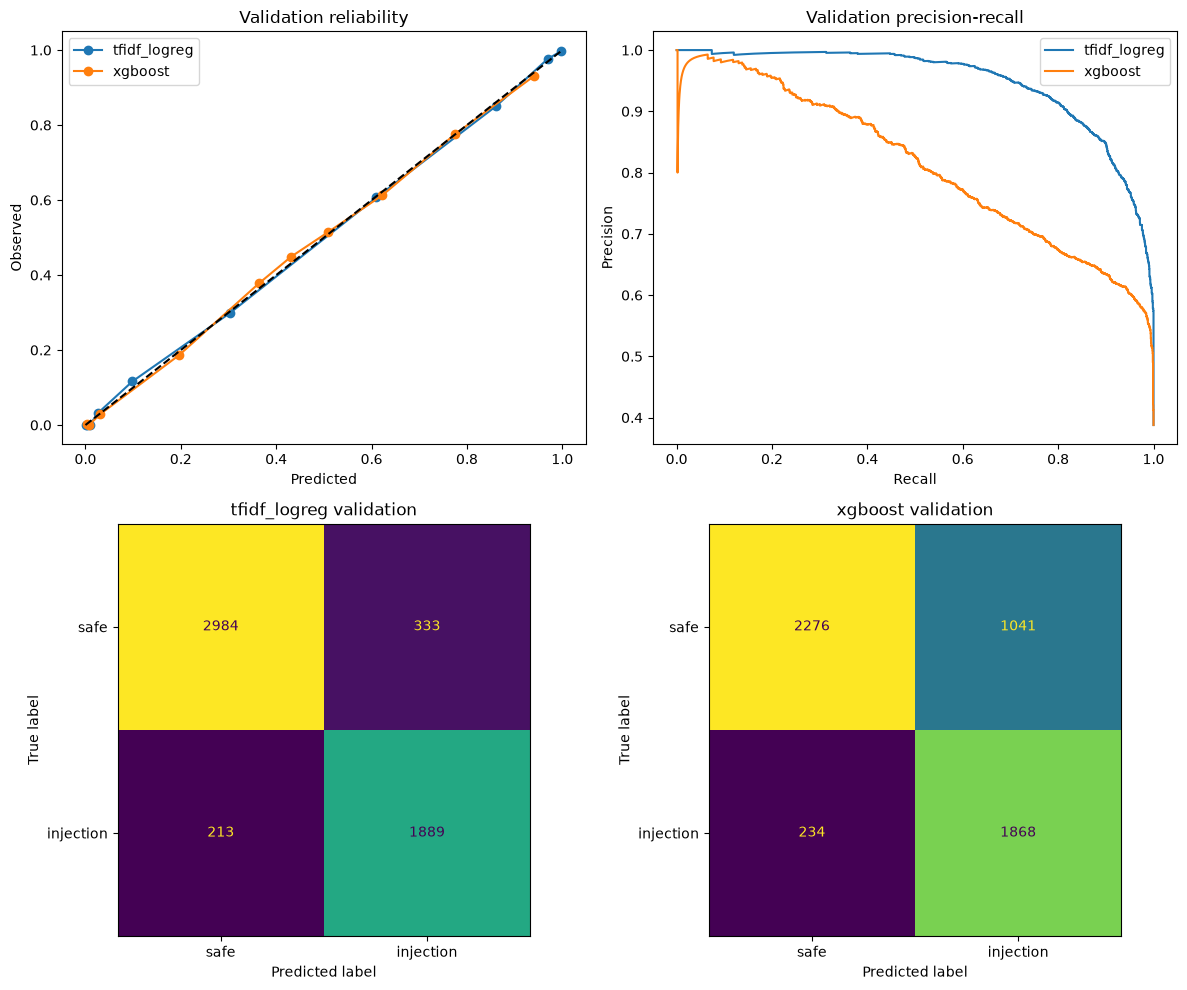

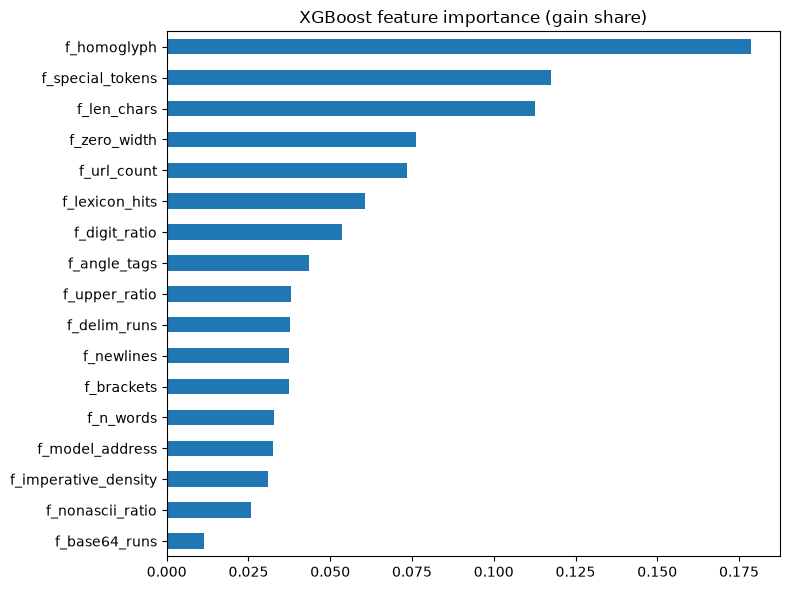

In [7]:
validation_probabilities = {"tfidf_logreg": logreg_val_probability, "xgboost": xgb_val_probability}
validation_metrics = {"tfidf_logreg": logreg_validation, "xgboost": xgb_validation}
thresholds = {"tfidf_logreg": logreg_threshold, "xgboost": xgb_threshold}
validation_recall_at_fpr = {name: recall_at_fpr(y["val"], probabilities) for name, probabilities in validation_probabilities.items()}


def selection_key(model_name):
    metrics = validation_metrics[model_name]
    return (metrics["f1"], metrics["recall"], -metrics["false_positive_rate"])


chosen_model = max(sorted(validation_metrics), key=selection_key)
print(pd.DataFrame(validation_metrics).T[["threshold", "precision", "recall", "f1", "roc_auc", "average_precision", "brier", "false_positive_rate"]])
print()
print("validation recall at FPR budget:")
print(pd.DataFrame({name: {budget: row["recall"] for budget, row in table.items()} for name, table in validation_recall_at_fpr.items()}).T)
print("chosen model:", chosen_model)

figure, axes = plt.subplots(2, 2, figsize=(12, 10))
for name, probabilities in validation_probabilities.items():
    observed, predicted = calibration_curve(y["val"], probabilities, n_bins=10, strategy="quantile")
    axes[0, 0].plot(predicted, observed, marker="o", label=name)
    precision, recall, _ = precision_recall_curve(y["val"], probabilities)
    axes[0, 1].plot(recall, precision, label=name)
axes[0, 0].plot([0, 1], [0, 1], linestyle="--", color="black")
axes[0, 0].set(title="Validation reliability", xlabel="Predicted", ylabel="Observed")
axes[0, 1].set(title="Validation precision-recall", xlabel="Recall", ylabel="Precision")
axes[0, 0].legend(); axes[0, 1].legend()
for axis, name in zip(axes[1], ("tfidf_logreg", "xgboost")):
    predictions = (validation_probabilities[name] >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y["val"], predictions, labels=[0, 1], display_labels=["safe", "injection"], colorbar=False, ax=axis)
    axis.set_title(f"{name} validation")
figure.tight_layout()
figure.savefig(str(OUTPUT_DIR / "validation_diagnostics.png"), dpi=160)
plt.show()

importance = pd.Series(xgb_model.feature_importances_, index=FEATURE_COLS).sort_values()
importance.plot.barh(figsize=(8, 6), title="XGBoost feature importance (gain share)")
plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / "xgboost_feature_importance.png"), dpi=160)
plt.show()


## 7. Final Locked Evaluation and Artifact Manifest

`test` and `adversarial_test` are opened here for the first time. Each number is reported with its
95% bootstrap interval; recall at the three FPR budgets is reported on test; slices by source and
by shape show where each baseline fails. Nothing below feeds back into selection.


In [8]:
def predict_logreg(name):
    return apply_calibrator(logreg_calibrator, logreg.predict_proba(X_tfidf[name])[:, 1])


def predict_xgb(name):
    return apply_calibrator(xgb_calibrator, xgb_model.predict_proba(X_feat[name])[:, 1])


test_probabilities = {"tfidf_logreg": predict_logreg("test"), "xgboost": predict_xgb("test")}
adversarial_probabilities = {"tfidf_logreg": predict_logreg("adversarial_test"), "xgboost": predict_xgb("adversarial_test")}

final_metrics = {
    "validation": validation_metrics,
    "validation_recall_at_fpr": validation_recall_at_fpr,
    "test": {name: binary_metrics(y["test"], probabilities, thresholds[name]) for name, probabilities in test_probabilities.items()},
    "test_bootstrap_95ci": {name: bootstrap_ci(y["test"], probabilities, thresholds[name], seed=SEED) for name, probabilities in test_probabilities.items()},
    "test_recall_at_fpr": {name: recall_at_fpr(y["test"], probabilities) for name, probabilities in test_probabilities.items()},
    "test_slices_by_source": {name: slice_metrics(frames["test"], probabilities, thresholds[name], "source") for name, probabilities in test_probabilities.items()},
    "test_slices_by_shape": {name: slice_metrics(frames["test"], probabilities, thresholds[name], "shape") for name, probabilities in test_probabilities.items()},
    "adversarial_test": {name: adversarial_metrics(probabilities, thresholds[name]) for name, probabilities in adversarial_probabilities.items()},
    "adversarial_test_by_kind": {name: slice_metrics(frames["adversarial_test"], probabilities, thresholds[name], "aug_kind") for name, probabilities in adversarial_probabilities.items()},
}

package_versions = {
    "python": platform.python_version(),
    "numpy": package_version("numpy"), "pandas": package_version("pandas"), "scipy": package_version("scipy"),
    "scikit_learn": package_version("scikit-learn"), "torch": package_version("torch"),
    "xgboost": package_version("xgboost"), "matplotlib": package_version("matplotlib"),
    "cuda_available": torch.cuda.is_available(), "cuda_version": torch.version.cuda,
    "cuda_device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "mps_available": bool(getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()),
    "xgboost_device": XGB_CONFIG["device"],
}
run_manifest = {
    "run_id": run_id,
    "dataset_version": DATASET_VERSION,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "phase1_config_fingerprint": PHASE1_FINGERPRINT,
    "phase1_manifest": str(MANIFEST_PATH),
    "source_files": {name: str(path) for name, path in SPLIT_PATHS.items()},
    "source_counts": {name: {k: v for k, v in counts.items() if not isinstance(v, dict)} for name, counts in manifest["counts"].items()},
    "feature_columns": FEATURE_COLS,
    "models": ["tfidf_logreg", "xgboost"],
    "chosen_model": chosen_model,
    "selection_data": "val.parquet only",
    "selection_criteria": ["higher_f1", "higher_recall", "lower_false_positive_rate"],
    "holdout_policy": "test and adversarial_test opened for prediction only after selection; lora_holdout untouched here",
    "xgboost_best_iteration": int(xgb_model.best_iteration),
    "xgboost_stopped_early": bool(xgb_stopped_early),
}

atomic_json({"thresholds": thresholds, "fpr_budget_thresholds_val": validation_recall_at_fpr}, OUTPUT_DIR / "thresholds.json")
atomic_json(final_metrics, OUTPUT_DIR / "metrics.json")
atomic_json({"seed": SEED, "tfidf": TFIDF_CONFIG, "logreg": LOGREG_CONFIG, "xgboost": XGB_CONFIG}, OUTPUT_DIR / "config.json")
atomic_json(FEATURE_COLS, OUTPUT_DIR / "feature_columns.json")
atomic_json(package_versions, OUTPUT_DIR / "package_versions.json")
atomic_json(run_manifest, OUTPUT_DIR / "run_manifest.json")

print("FINAL LOCKED TEST")
print(pd.DataFrame(final_metrics["test"]).T[["threshold", "precision", "recall", "f1", "roc_auc", "average_precision", "brier", "false_positive_rate"]])
print()
print("95% bootstrap CI on test:")
for name, ci in final_metrics["test_bootstrap_95ci"].items():
    print(" ", name, {k: (round(v["low"], 4), round(v["high"], 4)) for k, v in ci.items()})
print()
print("test recall at FPR budget:")
print(pd.DataFrame({name: {budget: row["recall"] for budget, row in table.items()} for name, table in final_metrics["test_recall_at_fpr"].items()}).T)
print()
print("test slices by shape:")
for name, slices in final_metrics["test_slices_by_shape"].items():
    print(" ", name, {k: {m: round(v, 4) for m, v in row.items() if m in ("recall", "false_positive_rate", "f1")} for k, row in slices.items()})
print()
print("test slices by source (recall for injection sources, FPR for safe sources):")
for name, slices in final_metrics["test_slices_by_source"].items():
    print(" ", name)
    for source, row in slices.items():
        print(f"    {source:32s} rows={row['rows']:>6,}  " + "  ".join(f"{m}={row[m]:.4f}" for m in ("recall", "false_positive_rate", "f1") if m in row))
print()
print("FINAL ADVERSARIAL TEST")
print(pd.DataFrame(final_metrics["adversarial_test"]).T)
print("selected:", chosen_model)
print("artifacts:", OUTPUT_DIR)


FINAL LOCKED TEST
              threshold  precision    recall        f1   roc_auc  \
tfidf_logreg   0.420206   0.854628  0.900571  0.876998  0.970372   
xgboost        0.374149   0.643427  0.882493  0.744233  0.882356   

              average_precision     brier  false_positive_rate  
tfidf_logreg           0.956309  0.066726             0.097076  
xgboost                0.824288  0.135076             0.309919  

95% bootstrap CI on test:
  tfidf_logreg {'average_precision': (0.9502, 0.9622), 'roc_auc': (0.9667, 0.9741), 'f1': (0.8662, 0.8871), 'recall': (0.8874, 0.9125), 'false_positive_rate': (0.0876, 0.1069)}
  xgboost {'average_precision': (0.8095, 0.8385), 'roc_auc': (0.8739, 0.8907), 'f1': (0.7307, 0.7578), 'recall': (0.8683, 0.8953), 'false_positive_rate': (0.2941, 0.3245)}

test recall at FPR budget:
              fpr_0.01  fpr_0.005  fpr_0.001
tfidf_logreg  0.641294   0.538535   0.423406
xgboost       0.279734   0.207422   0.136537

test slices by shape:
  tfidf_logreg {'cha

## 8. Report

Writes `reports/<UTC stamp>_phase_2_baselines_<version>_<fingerprint>/report.md` with the validation and locked-test
tables, bootstrap intervals, recall at the FPR budgets, slices, the adversarial set, and copies of
the diagnostic plots beside it.


In [9]:
# ---- Report: tracked Markdown summary of this run, written to reports/ with its plots beside it ----
import shutil

REPORTS_DIR = PROJECT_DIR / "reports"
RUN_STAMP = datetime.now(timezone.utc).strftime("%Y-%m-%d_%H%M%SZ")


def report_dir(run_name):
    # One folder per run: reports/<UTC stamp>_<phase>_<version>_<fingerprint>/ holding report.md and its plots.
    path = REPORTS_DIR / f"{RUN_STAMP}_{run_name}"
    path.mkdir(parents=True, exist_ok=True)
    return path


def md_table(frame, floatfmt="{:.4f}", index=True):
    frame = pd.DataFrame(frame)
    cols = [str(c) for c in frame.columns]
    header = ([""] if index else []) + cols
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    for idx, row in frame.iterrows():
        cells = []
        for v in row.tolist():
            if v is None or (isinstance(v, float) and np.isnan(v)):
                cells.append("")
            elif isinstance(v, (float, np.floating)):
                cells.append(floatfmt.format(float(v)))
            elif isinstance(v, (bool, np.bool_)):
                cells.append("yes" if v else "no")
            else:
                cells.append(str(v).replace("|", "\\|").replace("\n", " "))
        lines.append("| " + " | ".join(([str(idx)] if index else []) + cells) + " |")
    return "\n".join(lines)


def write_report(name, title, sections):
    # sections: list of (heading, markdown body). Atomic write, LF endings.
    parts = [f"# {title}", f"_Generated {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')}_"]
    for heading, body in sections:
        parts.append(f"## {heading}\n\n{body}" if heading else body)
    path = report_dir(name) / "report.md"
    tmp = Path(str(path) + ".tmp")
    tmp.write_text("\n\n".join(parts) + "\n", encoding="utf-8", newline="\n")
    os.replace(tmp, path)
    print("report written:", path)
    return path


def report_asset(run_name, filename):
    # Plots live beside report.md and are referenced by bare file name.
    return report_dir(run_name), filename

run_name = f"phase_2_baselines_{DATASET_VERSION}_{PHASE1_FINGERPRINT[:16]}"
asset_dir, _ = report_asset(run_name, "")
plots = []
for filename in ("validation_diagnostics.png", "xgboost_feature_importance.png"):
    if (OUTPUT_DIR / filename).exists():
        shutil.copyfile(OUTPUT_DIR / filename, asset_dir / filename)
        plots.append(f"![{filename}]({filename})")

headline_cols = ["threshold", "precision", "recall", "f1", "roc_auc", "average_precision", "brier", "log_loss", "false_positive_rate"]
ci_rows = {name: {k: f"{v['low']:.4f} to {v['high']:.4f}" for k, v in ci.items()} for name, ci in final_metrics["test_bootstrap_95ci"].items()}
rafpr = {name: {budget: row["recall"] for budget, row in table.items()} for name, table in final_metrics["test_recall_at_fpr"].items()}
shape_rows = {(name, shape): {m: row.get(m) for m in ("rows", "recall", "false_positive_rate", "f1")}
              for name, slices in final_metrics["test_slices_by_shape"].items() for shape, row in slices.items()}
source_rows = {(name, source): {m: row.get(m) for m in ("rows", "recall", "false_positive_rate", "f1")}
               for name, slices in final_metrics["test_slices_by_source"].items() for source, row in slices.items()}
adv_kind = {(name, kind): {"rows": row["rows"], "recall": row.get("recall")}
            for name, slices in final_metrics["adversarial_test_by_kind"].items() for kind, row in slices.items()}

write_report(run_name, f"Phase 2 Report: Baselines on dataset {DATASET_VERSION} ({PHASE1_FINGERPRINT[:16]})", [
    ("Run", f"- Run ID: `{run_id}`\n- Dataset fingerprint: `{PHASE1_FINGERPRINT}`\n- Chosen baseline (val F1, recall, FPR): **{chosen_model}**\n- XGBoost best iteration: {xgb_model.best_iteration} ({'early stopping fired' if xgb_stopped_early else 'cap reached'})\n- Device: {package_versions['device'] if 'device' in package_versions else package_versions['xgboost_device']}, torch {package_versions['torch']}, xgboost {package_versions['xgboost']}\n- Artifacts: `{OUTPUT_DIR.relative_to(PROJECT_DIR)}`"),
    ("Validation (selection data)", md_table(pd.DataFrame(validation_metrics).T[headline_cols])),
    ("Locked test", md_table(pd.DataFrame(final_metrics["test"]).T[headline_cols]) + "\n\n95% bootstrap intervals (1,000 resamples):\n\n" + md_table(pd.DataFrame(ci_rows).T)),
    ("Recall at FPR budget (test)", md_table(pd.DataFrame(rafpr).T)),
    ("Test slices by shape", md_table(pd.DataFrame(shape_rows).T)),
    ("Test slices by source", md_table(pd.DataFrame(source_rows).T)),
    ("Locked adversarial test", md_table(pd.DataFrame(final_metrics["adversarial_test"]).T) + "\n\nBy variant kind:\n\n" + md_table(pd.DataFrame(adv_kind).T)),
    ("Plots", "\n\n".join(plots) if plots else "_no plots found in the run directory_"),
])


report written: /workspace/training/prompt-injection-nn/reports/2026-10-09_171747Z_phase_2_baselines_v3_a4c8dd4786013cfd/report.md


PosixPath('/workspace/training/prompt-injection-nn/reports/2026-10-09_171747Z_phase_2_baselines_v3_a4c8dd4786013cfd/report.md')